In [32]:
from qiskit import QuantumRegister, QuantumCircuit
from qiskit_aer import Aer
from qiskit import quantum_info as qi
from qiskit.visualization import plot_bloch_multivector
import numpy as np

#### create a quantum circuit built of a quantum register containing one qubit
#### apply the $X$ gate to the qubit

In [10]:
qr = QuantumRegister(1, "qreg")
qc = QuantumCircuit(qr)
qc.x(qr[0])

#### draw the circuit; more graphics with the 'mpl' option

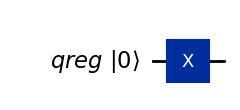

In [13]:
#qc.draw()
qc.draw('mpl', initial_state=True)

#### define a simulator for state vectors

In [17]:
backend = Aer.get_backend('statevector_simulator')

#### run the above circuit through this simulator, get the result and extract the final state vector

In [18]:
psi_f = backend.run(qc).result().get_statevector()

In [19]:
print(psi_f)

Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


#### define a simulator for unitaries

In [20]:
backend = Aer.get_backend('unitary_simulator')

#### run it, get the result and extract the unitary operator corresponding to the above circuit

In [21]:
U = backend.run(qc).result().get_unitary(qc, decimals = 3)

In [22]:
print(U)

Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


#### a simple method to get the circuit unitary, without doing a simulation

In [25]:
U = qi.Operator.from_circuit(qc)
print(U)

Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


#### create a similar circuit, but with a rotation $R_{y}(\pi/4)$ instead of the $X$ gate

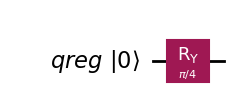

In [30]:
qr = QuantumRegister(1, "qreg")
qc = QuantumCircuit(qr)
qc.ry(np.pi/4, qr[0])
qc.draw('mpl', initial_state=True)

#### state vector simulation

In [31]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
print(psi_f)

Statevector([0.92387953+0.j, 0.38268343+0.j],
            dims=(2,))


#### plot on the Bloch sphere

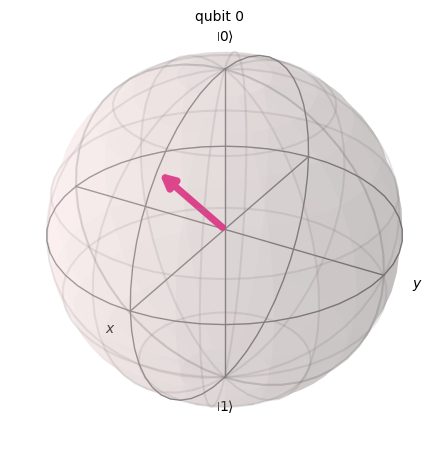

In [33]:
plot_bloch_multivector(psi_f)

In [34]:
print(qi.Operator.from_circuit(qc))

Operator([[ 0.92387953+0.j, -0.38268343+0.j],
          [ 0.38268343+0.j,  0.92387953+0.j]],
         input_dims=(2,), output_dims=(2,))


#### continue the circuit by adding an $X$ gate after the $R_{y}$ gate

In [35]:
qc.x(qr[0])
qc.draw()

┌─────────┐┌───┐
qreg: ┤ Ry(π/4) ├┤ X ├
      └─────────┘└───┘

In [36]:
print(qi.Operator.from_circuit(qc))

Operator([[ 0.38268343+0.j,  0.92387953+0.j],
          [ 0.92387953+0.j, -0.38268343+0.j]],
         input_dims=(2,), output_dims=(2,))


In [37]:
qi.Operator.from_circuit(qc).is_unitary()

True

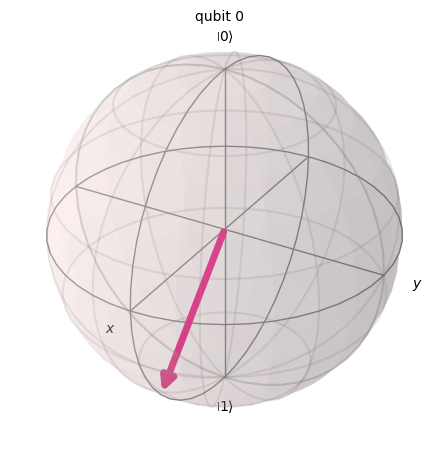

In [38]:
psi_f = backend.run(qc).result().get_statevector()
plot_bloch_multivector(psi_f)